# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from features_utils import clean_features,engineer_features
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import StratifiedShuffleSplit


### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [3]:
# # If you work with Google Colaboratory, please run this as well.
# from google.colab import drive
# drive.mount('/content/drive')

Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIGlobal/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [4]:
# # Specify the directory where this notebook is located after %cd.
# %cd "/content/drive/MyDrive/WhereThisNotebookIsLocated"

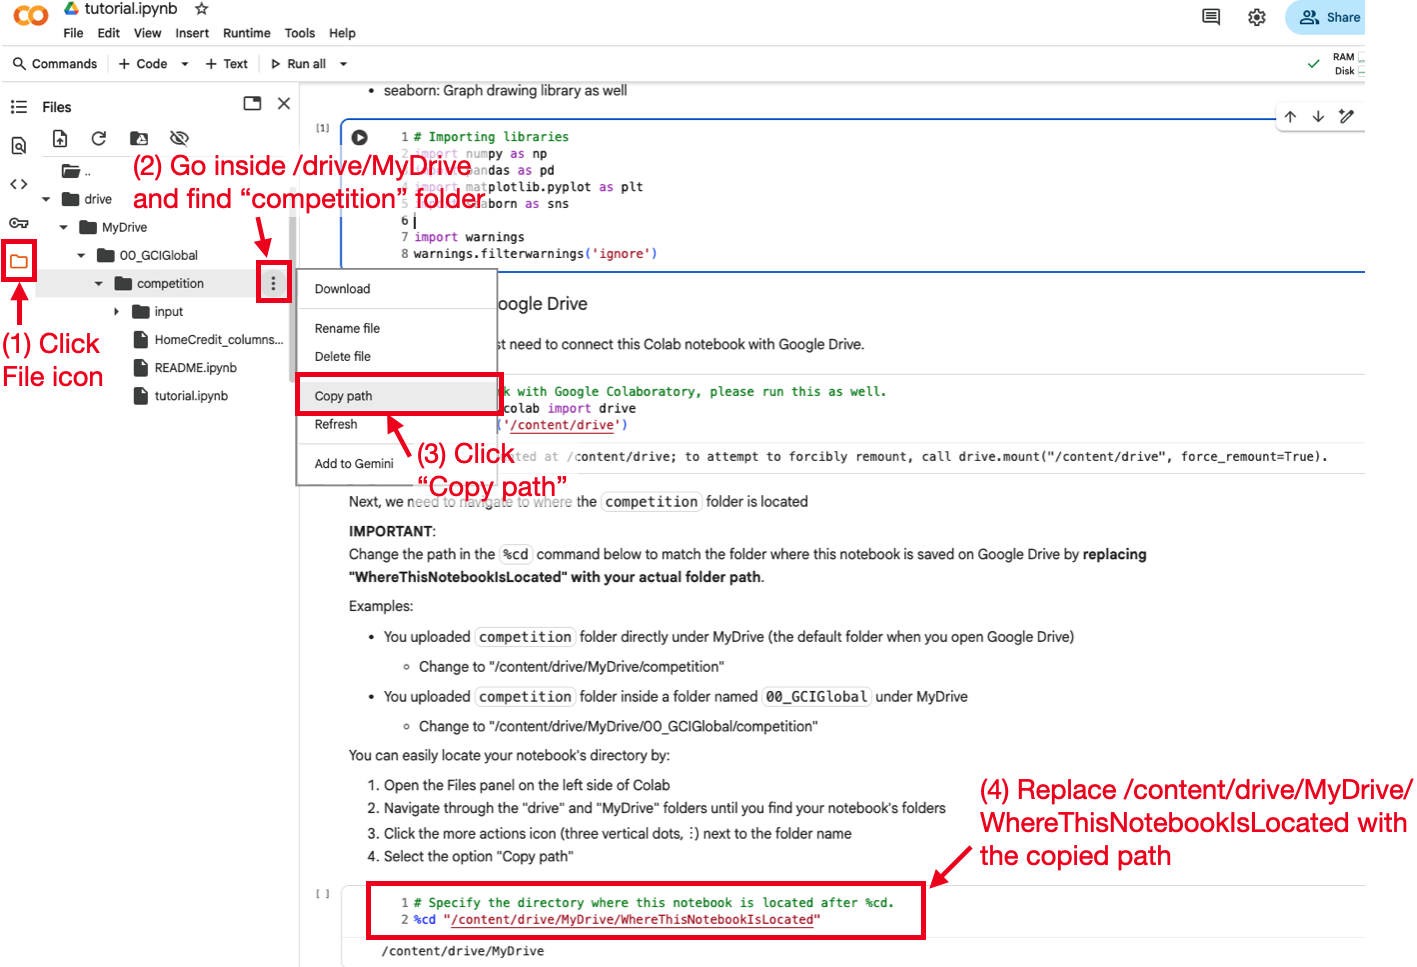

Run the cell below to check if the path is correctly set.

In [5]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [6]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [7]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,...,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,...,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,...,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [8]:
# Check test data
print(f"test shape: {test.shape}")
train.info()

test shape: (61500, 33)
<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  str    
 2   CODE_GENDER                 171202 non-null  str    
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  str    
 9   NAME_EDUCATION_TYPE         171202 non-null  str    
 10  NAME_FAMILY_STATUS          171202 non-null  str    
 11  NAME_HOUSING_TYPE           171202 non-null  str    
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  D

In [9]:
train.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


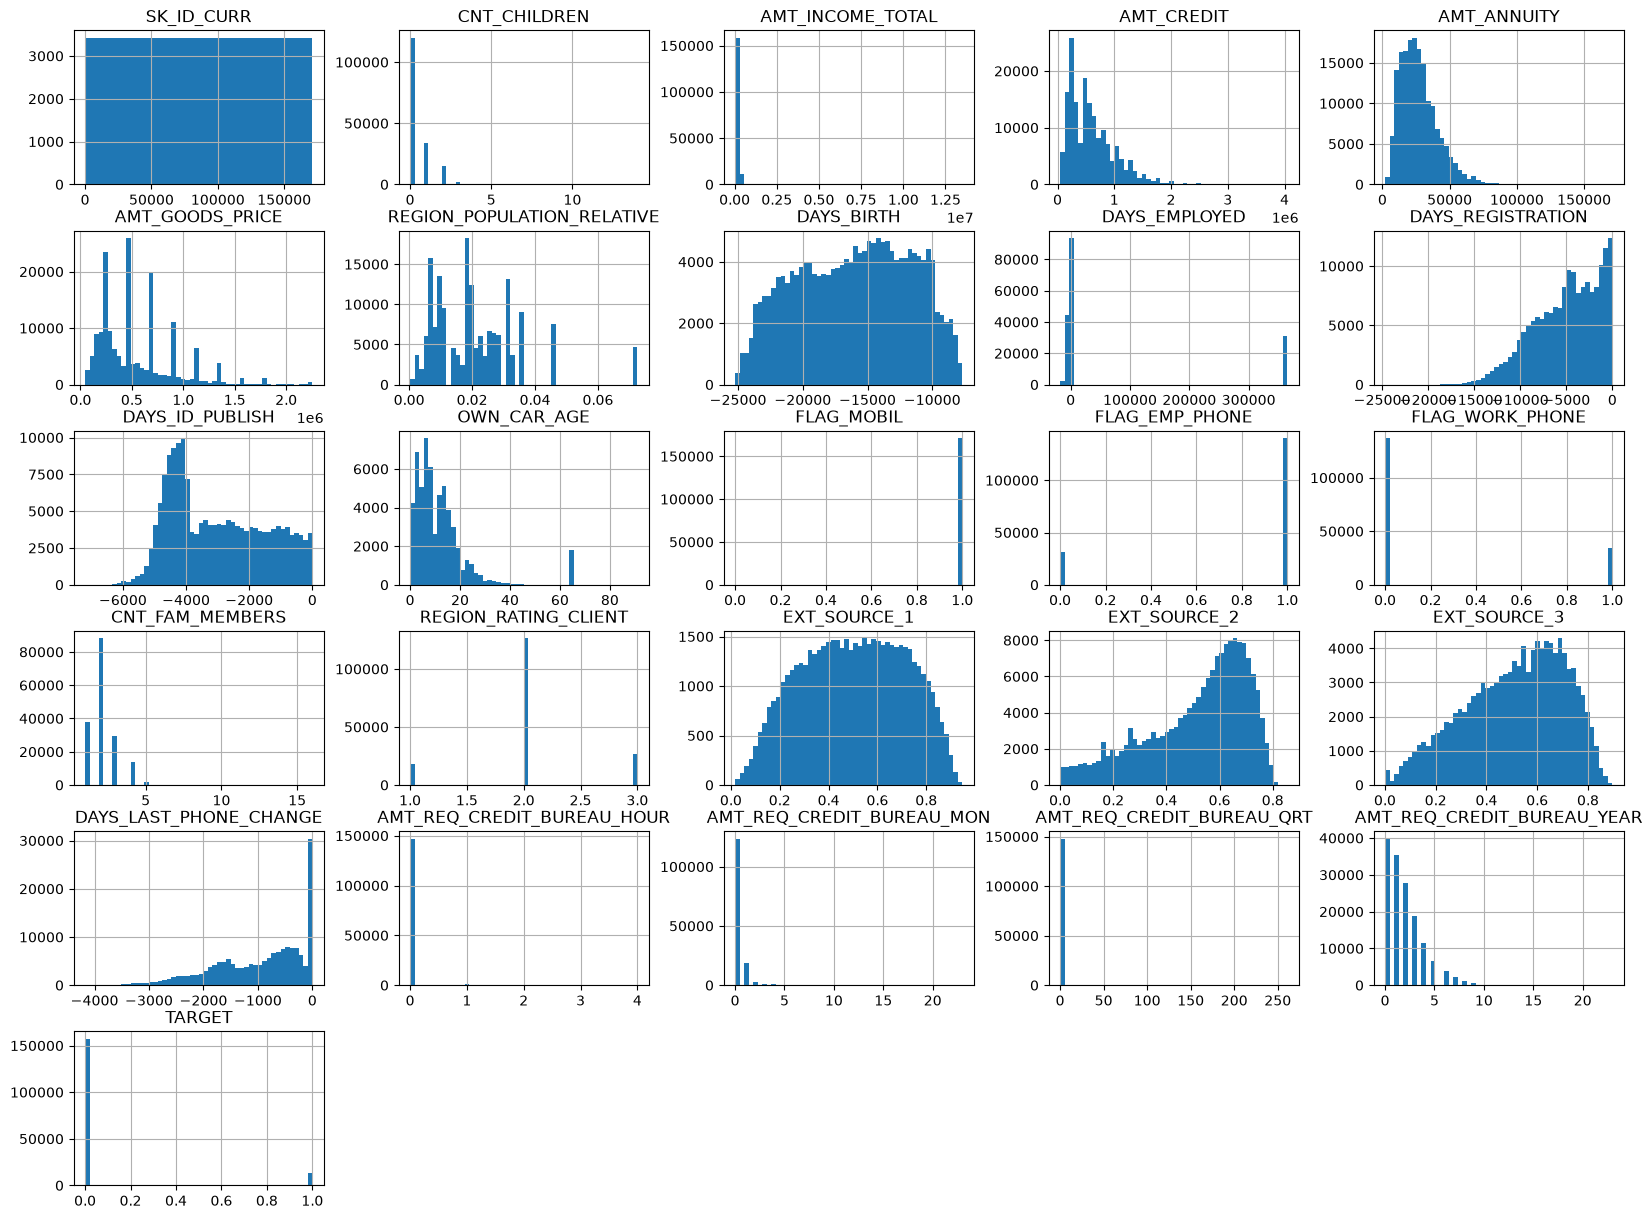

In [10]:

import matplotlib.pyplot as plt
train.hist(bins=50, figsize=(20,15))
plt.show()

In [11]:
# newFeatureTrain = train.copy()
# # 1. Loan size relative to income
# newFeatureTrain["CREDIT_INCOME_RATIO"] = (
#     newFeatureTrain["AMT_CREDIT"] / newFeatureTrain["AMT_INCOME_TOTAL"]
# )

# # 2. Regular payment relative to income
# newFeatureTrain["ANNUITY_INCOME_RATIO"] = (
#     newFeatureTrain["AMT_ANNUITY"] / newFeatureTrain["AMT_INCOME_TOTAL"]
# )

# # 3. Loan amount relative to goods price
# newFeatureTrain["CREDIT_GOODS_RATIO"] = (
#     newFeatureTrain["AMT_CREDIT"] / newFeatureTrain["AMT_GOODS_PRICE"]
# )

# # 4. Applicant's age in years
# newFeatureTrain["AGE_YEARS"] = -newFeatureTrain["DAYS_BIRTH"] / 365.25

# # 5. Employment duration in years
# newFeatureTrain["EMPLOYMENT_YEARS"] = -newFeatureTrain["DAYS_EMPLOYED"] / 365.25

# # 6. Income per family member
# newFeatureTrain["INCOME_PER_PERSON"] = (
#     newFeatureTrain["AMT_INCOME_TOTAL"] / newFeatureTrain["CNT_FAM_MEMBERS"]
# )

Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

In [12]:
# # Focus on 5 features
# use_features = [
#     "DAYS_EMPLOYED",
#     # add new features to use here
# ]
# target = train["TARGET"].values

# train = train[use_features]
# train["TARGET"] = target
# test = test[use_features]

Let's check the data once again.

In [13]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)
train['DAYS_EMPLOYED'].value_counts()

train shape: (171202, 34)


DAYS_EMPLOYED
 365243    30898
-200         106
-224          90
-384          85
-230          84
           ...  
-11691         1
-9319          1
-10069         1
-12692         1
-10945         1
Name: count, Length: 11178, dtype: int64

In [14]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)
test.sort_values(by="DAYS_EMPLOYED", ascending=False)["DAYS_EMPLOYED"].value_counts()

test shape: (61500, 33)


DAYS_EMPLOYED
 365243    10565
-254          38
-230          37
-106          36
-133          36
           ...  
-16495         1
-16499         1
-16767         1
-16836         1
-16852         1
Name: count, Length: 8491, dtype: int64

### **[Next Steps]**
> + Try adding more features, starting with the ones that you think are more relevant for predicting default probability. Check `HomeCredit_columns_description.xlsx` to understand what each column represents.
> + When you add new features, always restart from [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1) by reloading the dataset.

## 3.Visualizing and Understanding the Data

The first thing we need to do before building the machine learning model is to **understand the data**. We do this by visualizing and analyzing, to deepen our understanding of data distribution, missing values, outliers, correlations, and etc. The results of the analysis obtained at this stage will be useful for preprocessing, feature creation, and selection of machine learning models, which are all important to building models with better prediction ability.

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [15]:
# Check missing values of train data
train.isnull().sum()

SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                   112992
FLAG_MOBIL                         0
FLAG_EMP_PHONE                     0
FLAG_WORK_PHONE                    0
OCCUPATION_TYPE                    0
CNT_FAM_MEMBERS                    2
REGION_RATING_CLIENT               0
ORGANIZATION_TYPE                  0
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
E

In [16]:
# Check missing values of test data
test.isnull().sum()

SK_ID_CURR                        0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
CNT_CHILDREN                      0
AMT_INCOME_TOTAL                  0
AMT_CREDIT                        0
AMT_ANNUITY                       0
AMT_GOODS_PRICE                   0
NAME_INCOME_TYPE                  0
NAME_EDUCATION_TYPE               0
NAME_FAMILY_STATUS                0
NAME_HOUSING_TYPE                 0
REGION_POPULATION_RELATIVE        0
DAYS_BIRTH                        0
DAYS_EMPLOYED                     0
DAYS_REGISTRATION                 0
DAYS_ID_PUBLISH                   0
OWN_CAR_AGE                   40909
FLAG_MOBIL                        0
FLAG_EMP_PHONE                    0
FLAG_WORK_PHONE                   0
OCCUPATION_TYPE                   0
CNT_FAM_MEMBERS                   0
REGION_RATING_CLIENT              0
ORGANIZATION_TYPE                 0
EXT_SOURCE_1                  42912
EXT_SOURCE_2                    130
EXT_SOURCE_3                

In [17]:
train["DAYS_REGISTRATION"].value_counts()

DAYS_REGISTRATION
-1.0        64
-6.0        59
-7.0        53
-2.0        52
-3.0        51
            ..
-15002.0     1
-16240.0     1
-14495.0     1
-14833.0     1
-13148.0     1
Name: count, Length: 14909, dtype: int64

We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

#### TARGET column

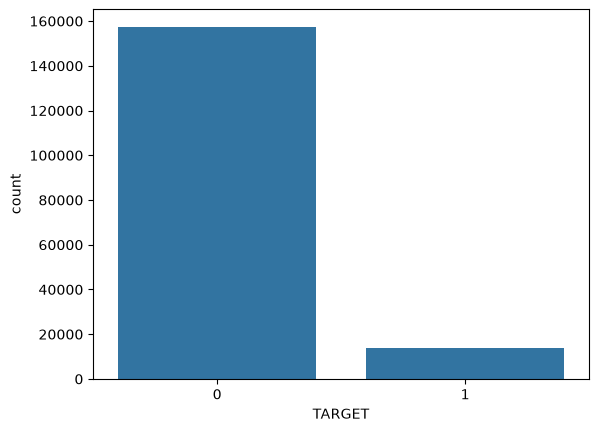

In [18]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

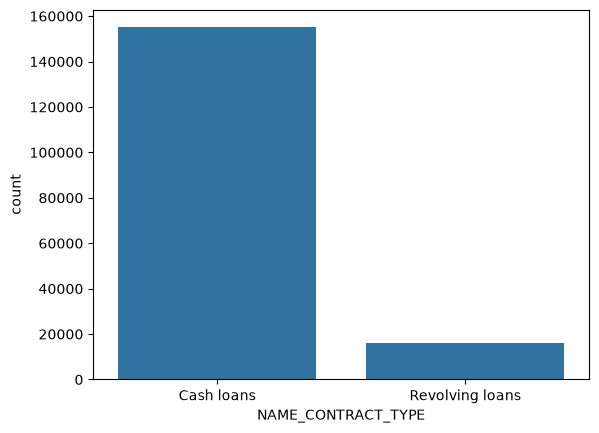

In [19]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

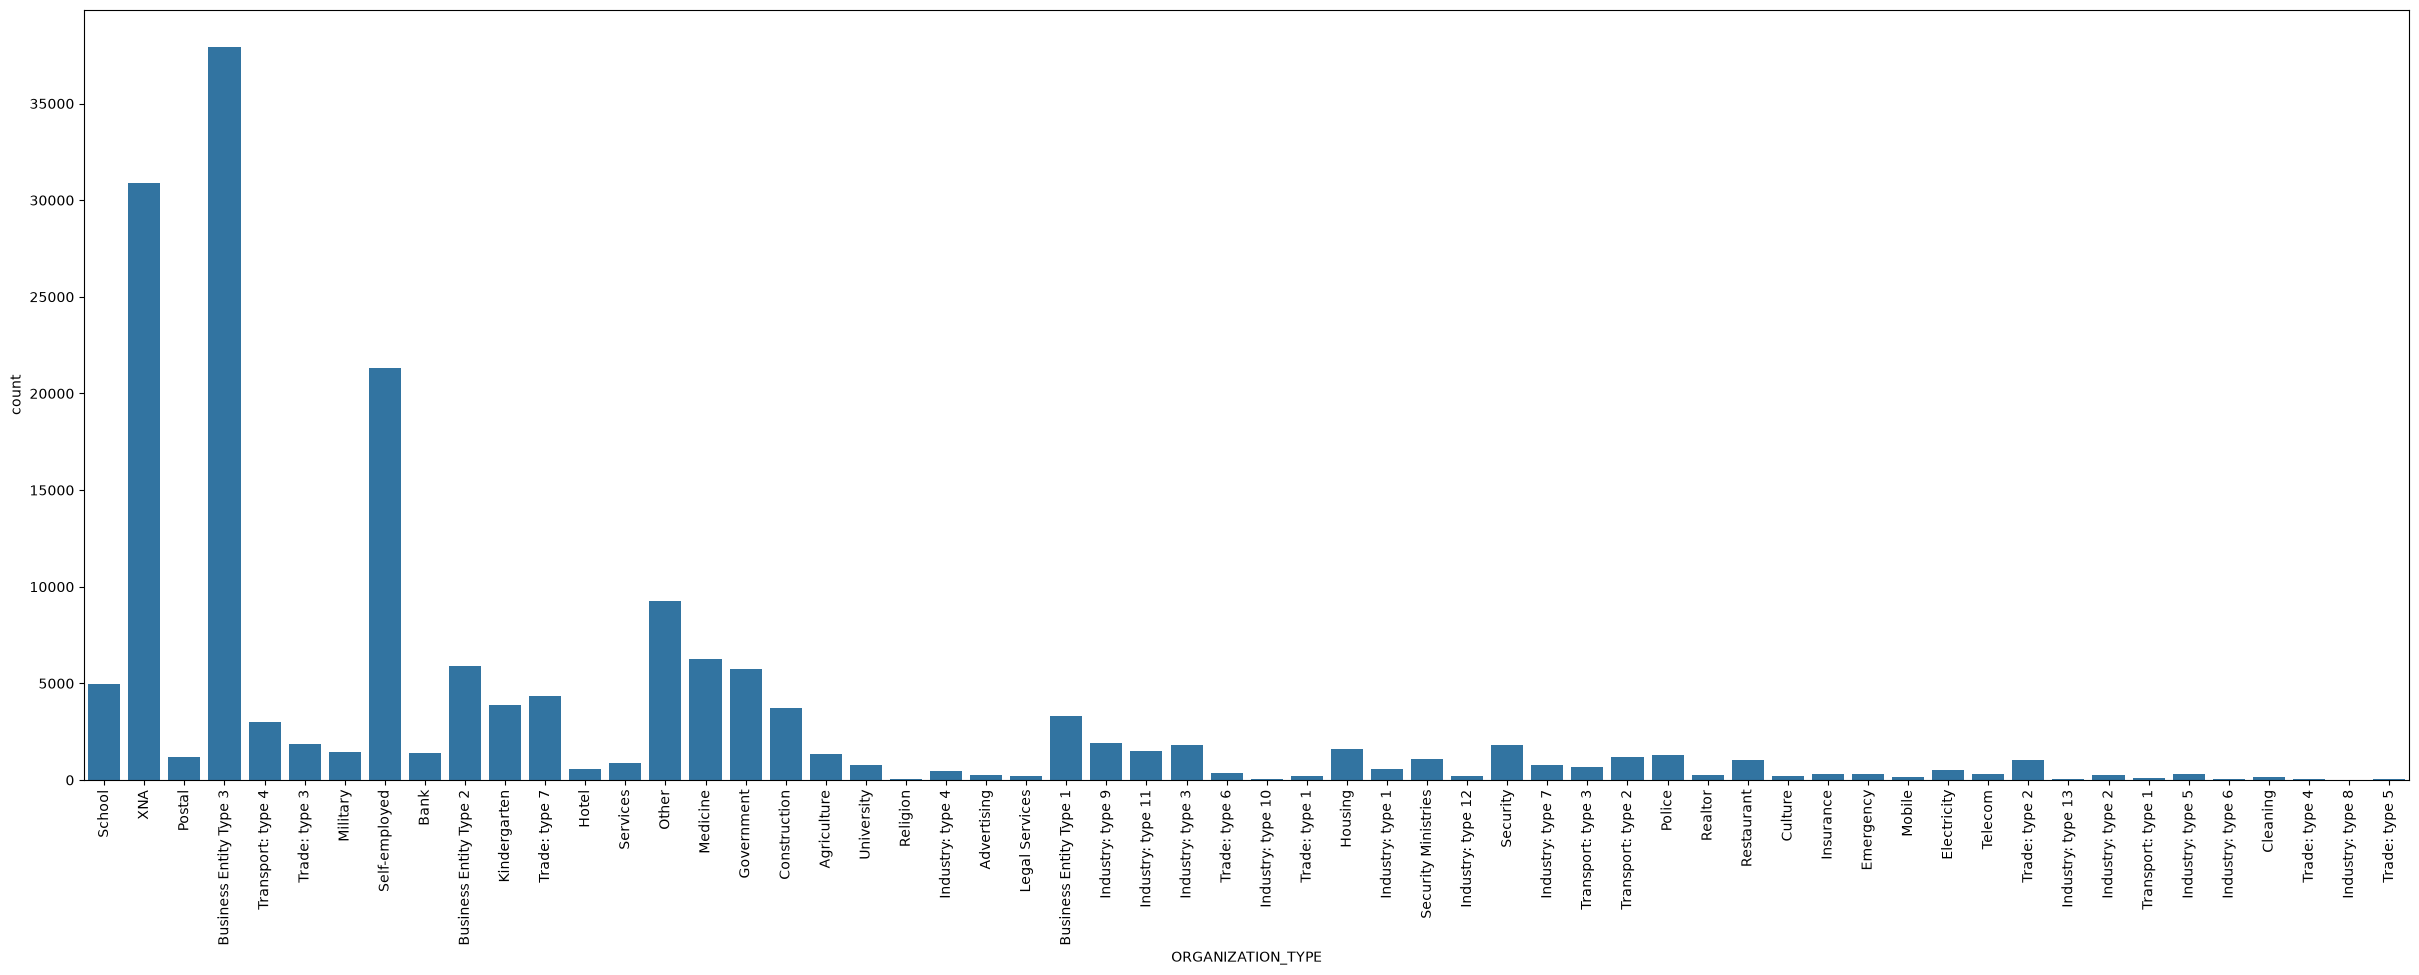

In [20]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

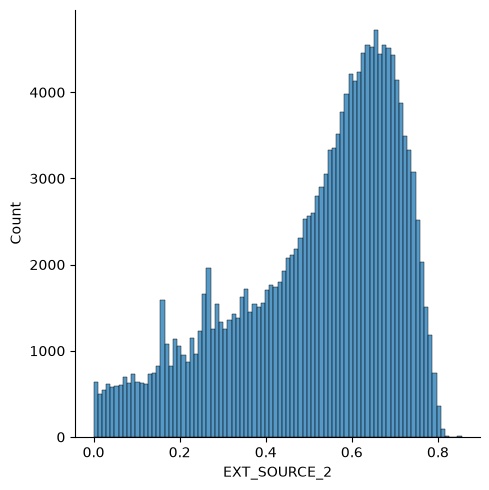

In [21]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

#### AMT_INCOME_TOTAL column

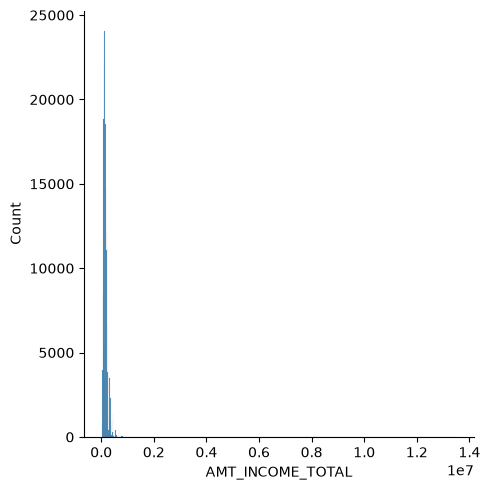

In [22]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

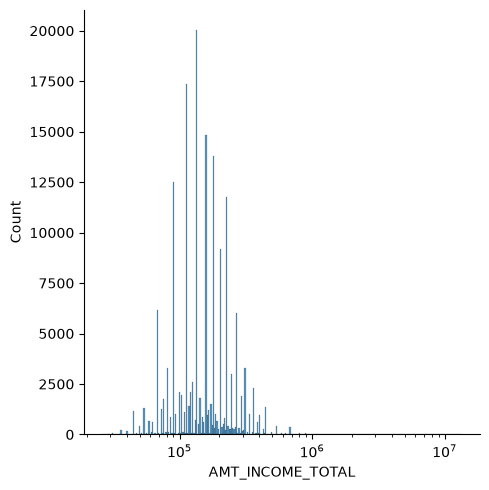

In [23]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [24]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [25]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

AMT_INCOME_TOTAL
135000.0    19969
112500.0    17320
157500.0    14772
180000.0    13791
90000.0     12481
225000.0    11573
202500.0     9128
67500.0      6130
270000.0     6006
81000.0      3295
Name: count, dtype: int64

In [26]:
train["AMT_INCOME_TOTAL"]

0         112500.0
1         225000.0
2          54000.0
3          67500.0
4         157500.0
            ...   
171197     83250.0
171198    247500.0
171199    292500.0
171200    112500.0
171201    108000.0
Name: AMT_INCOME_TOTAL, Length: 171202, dtype: float64

It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

#### OWN_CAR_AGE column

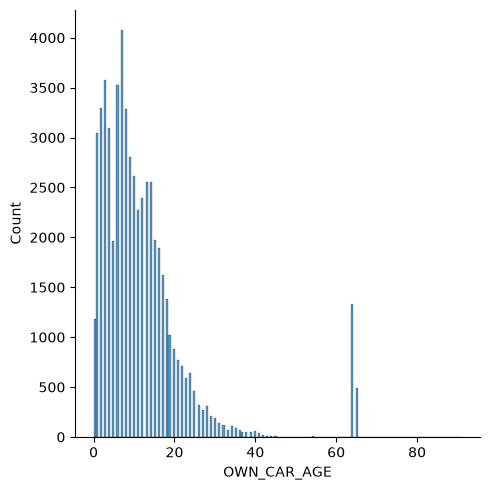

In [27]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

In [28]:
train.groupby("OCCUPATION_TYPE")["TARGET"].agg(
    ["mean", "count"]
).sort_values("mean", ascending=False)

,mean,count
OCCUPATION_TYPE,,
Low-skill Laborers,0.162349,1158
Waiters/barmen staff,0.128514,747
Drivers,0.117357,10353
Security staff,0.109542,3752
Laborers,0.103994,30723
Cooking staff,0.103788,3353
Sales staff,0.096386,17793
Cleaning staff,0.094663,2567
Secretaries,0.082677,762


In [29]:
cleanedTrain = clean_features(train)
cleanedTest = clean_features(test)

In [30]:
cleanedTrain = engineer_features(train)
cleanedTest = engineer_features(test)

        SK_ID_CURR NAME_CONTRACT_TYPE CODE_GENDER  CNT_CHILDREN  \
0                0         Cash loans           F             0   
1                1         Cash loans           F             0   
2                2         Cash loans           F             0   
3                3         Cash loans           F             0   
4                4         Cash loans           M             0   
...            ...                ...         ...           ...   
171197      171197         Cash loans           M             0   
171198      171198         Cash loans           F             0   
171199      171199         Cash loans           F             2   
171200      171200         Cash loans           M             0   
171201      171201         Cash loans           F             0   

        AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  \
0               112500.0    755190.0      36328.5         675000.0   
1               225000.0    585000.0      16893.0      

In [31]:
cleanedTrain.info()

<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 42 columns):
 #   Column                      Non-Null Count   Dtype   
---  ------                      --------------   -----   
 0   SK_ID_CURR                  171202 non-null  int64   
 1   NAME_CONTRACT_TYPE          171202 non-null  category
 2   CODE_GENDER                 171202 non-null  category
 3   CNT_CHILDREN                171202 non-null  int64   
 4   AMT_INCOME_TOTAL            171202 non-null  float64 
 5   AMT_CREDIT                  171202 non-null  float64 
 6   AMT_ANNUITY                 171202 non-null  float64 
 7   AMT_GOODS_PRICE             171202 non-null  float64 
 8   NAME_INCOME_TYPE            171202 non-null  category
 9   NAME_EDUCATION_TYPE         171202 non-null  category
 10  NAME_FAMILY_STATUS          171202 non-null  category
 11  NAME_HOUSING_TYPE           171202 non-null  category
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64 
 13  DAYS_BIRTH

In [32]:
cleanedTrain.isnull().sum()

SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                   112992
FLAG_MOBIL                         0
FLAG_EMP_PHONE                     0
FLAG_WORK_PHONE                    0
OCCUPATION_TYPE                    0
CNT_FAM_MEMBERS                    2
REGION_RATING_CLIENT               0
ORGANIZATION_TYPE                  0
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
E

In [33]:
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
for train_index, test_index in split.split(cleanedTrain, cleanedTrain["TARGET"]):
    strat_train_set = cleanedTrain.loc[train_index]
    strat_test_set = cleanedTrain.loc[test_index]

strat_train_set["TARGET"].value_counts() / len(strat_train_set)

TARGET
0    0.919269
1    0.080731
Name: count, dtype: float64

In [34]:
strat_test_set["TARGET"].value_counts() / len(strat_test_set)

TARGET
0    0.919278
1    0.080722
Name: count, dtype: float64

In [35]:
X_train = strat_train_set.drop(columns=["TARGET"])
y_train = strat_train_set["TARGET"]

X_test = strat_test_set.drop(columns=["TARGET"])
y_test = strat_test_set["TARGET"]


In [36]:
print(X_train.select_dtypes(
    exclude=["number", "bool"]
).dtypes)

NAME_CONTRACT_TYPE     category
CODE_GENDER            category
NAME_INCOME_TYPE       category
NAME_EDUCATION_TYPE    category
NAME_FAMILY_STATUS     category
NAME_HOUSING_TYPE      category
OCCUPATION_TYPE        category
ORGANIZATION_TYPE      category
dtype: object


In [37]:
text_cols = X_train.select_dtypes(include=["object"]).columns
X_train[text_cols] = X_train[text_cols].astype("category")

In [38]:
print(X_train.select_dtypes(
    exclude=["number", "bool"]
).dtypes)

NAME_CONTRACT_TYPE     category
CODE_GENDER            category
NAME_INCOME_TYPE       category
NAME_EDUCATION_TYPE    category
NAME_FAMILY_STATUS     category
NAME_HOUSING_TYPE      category
OCCUPATION_TYPE        category
ORGANIZATION_TYPE      category
dtype: object


In [39]:
import optuna
import xgboost as xgb

from sklearn.model_selection import StratifiedKFold, cross_val_score

# Preserve the class distribution in each fold
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Calculate imbalance ratio using training data only
negatives = (y_train == 0).sum()
positives = (y_train == 1).sum()
class_ratio = negatives / positives


def objective(trial):

    params = {
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "tree_method": "hist",
        "random_state": 42,
        "n_jobs": -1,
        "enable_categorical": True,
        # Hyperparameters to optimize
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 1000, step=100
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.2, log=True
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 3, 10
        ),
        "min_child_weight": trial.suggest_float(
            "min_child_weight", 1, 10
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-4, 10, log=True
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 100, log=True
        ),

        # Initial class-imbalance strategy
        "scale_pos_weight": class_ratio
    }

    model = xgb.XGBClassifier(**params)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        n_jobs=1
    )

    return scores.mean()


# Create the optimization study
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

# Run 50 trials
study.optimize(objective, n_trials=50)

print("Best CV ROC-AUC:", study.best_value)
print("Best parameters:", study.best_params)

[I 2026-10-19 21:44:40,149] A new study created in memory with name: no-name-b573a34b-4888-437d-ba59-150cf3d1dbfe
[I 2026-10-19 21:45:46,098] Trial 0 finished with value: 0.7153067435653055 and parameters: {'n_estimators': 500, 'learning_rate': 0.17254716573280354, 'max_depth': 8, 'min_child_weight': 6.387926357773329, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 0.00019517224641449495, 'reg_lambda': 21.42302175774105}. Best is trial 0 with value: 0.7153067435653055.
[I 2026-10-19 21:46:12,449] Trial 1 finished with value: 0.7521212339095129 and parameters: {'n_estimators': 700, 'learning_rate': 0.08341106432362087, 'max_depth': 3, 'min_child_weight': 9.72918866945795, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 0.0008111941985431928, 'reg_lambda': 0.008260808399079604}. Best is trial 1 with value: 0.7521212339095129.
[I 2026-10-19 21:46:38,750] Trial 2 finished with value: 0.7456482136339165 and paramete

Best CV ROC-AUC: 0.7549891758240718
Best parameters: {'n_estimators': 600, 'learning_rate': 0.05473704248966453, 'max_depth': 3, 'min_child_weight': 4.634876569826447, 'subsample': 0.8402290137664281, 'colsample_bytree': 0.6178003989254139, 'reg_alpha': 0.00016796502494306515, 'reg_lambda': 0.012200995084909936}


In [ ]:
best_params = study.best_params.copy()

final_model = xgb.XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="auc",
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=class_ratio
)

# Train using all training rows
final_model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.6178003989254139
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
final_model.predict(X_test)

array([0, 1, 0, ..., 1, 1, 0], shape=(34241,))

In [43]:
from sklearn.metrics import roc_auc_score
y_probs = final_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_probs)
roc_auc

0.7525409693163966

In [ ]:
# Make predictions for the test data
# Change model name if needed
pred = rf.predict_proba(X_test_std)[:, 1]

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [ ]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

In [ ]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")